 **Intalling the relavant libraries**

In [1]:
pip install pandas numpy scikit-learn

Note: you may need to restart the kernel to use updated packages.


1. Mean/Median Imputation: Used for baseline grid metrics like grid frequency (50Hz/60Hz) where minor deviations can just be averaged out.
2. Forward/Backward Fill: Crucial for continuous sensor feeds. If a SCADA system drops a package for a fraction of a second, the last recorded thermal or current reading is the safest estimate for the missing gap.
3. KNN Imputation: Essential for multi-variable diagnostics like Battery Management Systems (BMS), where a missing temperature reading can be accurately guessed based on the active current draw and voltage levels of neighboring cells.


In [2]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer, KNNImputer

# 1. Create a sample EEE Dataset (e.g., Transformer Sensor Logs)
# It contains missing values (None/NaN) in voltage, current, and temperature data.
data = {
    'Timestamp': pd.date_range(start='2026-10-23 08:00', periods=6, freq='h'),
    'Voltage_V': [230.1, np.nan, 229.8, 230.5, np.nan, 230.2],
    'Current_A': [15.2, 14.8, np.nan, 15.5, 15.1, 14.9],
    'Temperature_C': [45.2, 47.0, 48.5, np.nan, 46.1, np.nan]
}

df = pd.DataFrame(data)
print("--- Original Dataset with Missing Values ---")
print(df)
print("\n" + "="*50 + "\n")

# 2. Find Missing Values
print("--- Finding Missing Values ---")
# Check which values are null
print("Null values per column:")
print(df.isnull().sum())
print("\nTotal missing values in dataset:", df.isnull().sum().sum())
print("\n" + "="*50 + "\n")

# 3. Data Imputation Techniques

# Technique A: Mean/Median Imputation (Using Pandas)
# Best for stable metrics where values revolve around an average.
df_mean_imputed = df.copy()
df_mean_imputed['Voltage_V'] = df_mean_imputed['Voltage_V'].fillna(df_mean_imputed['Voltage_V'].mean())
print("--- Technique A: Mean Imputed (Voltage Column) ---")
print(df_mean_imputed[['Timestamp', 'Voltage_V']])
print("\n" + "="*50 + "\n")

# Technique B: Forward Fill & Backward Fill (Using Pandas)
# Excellent for time-series sensor data where the next state is close to the previous state.
df_time_imputed = df.copy()
# ffill: propagates last valid observation forward; bfill: uses next valid observation backward
df_time_imputed['Current_A'] = df_time_imputed['Current_A'].ffill().bfill()
print("--- Technique B: Time-Series Forward/Backward Fill (Current Column) ---")
print(df_time_imputed[['Timestamp', 'Current_A']])
print("\n" + "="*50 + "\n")

# Technique C: K-Nearest Neighbors (KNN) Imputation (Using Scikit-learn)
# Best for complex EEE datasets where features are highly correlated (e.g., Voltage vs Current vs Temp).
df_knn = df.copy()
# Exclude timestamp column as KNN requires numerical data
features = ['Voltage_V', 'Current_A', 'Temperature_C']

# Initialize KNN Imputer (n_neighbors=2 for this small sample size)
knn_imputer = KNNImputer(n_neighbors=2)
df_knn[features] = knn_imputer.fit_transform(df_knn[features])

print("--- Technique C: Advanced KNN Imputed Dataset (All Columns) ---")
print(df_knn)


--- Original Dataset with Missing Values ---
            Timestamp  Voltage_V  Current_A  Temperature_C
0 2026-10-23 08:00:00      230.1       15.2           45.2
1 2026-10-23 09:00:00        NaN       14.8           47.0
2 2026-10-23 10:00:00      229.8        NaN           48.5
3 2026-10-23 11:00:00      230.5       15.5            NaN
4 2026-10-23 12:00:00        NaN       15.1           46.1
5 2026-10-23 13:00:00      230.2       14.9            NaN


--- Finding Missing Values ---
Null values per column:
Timestamp        0
Voltage_V        2
Current_A        1
Temperature_C    2
dtype: int64

Total missing values in dataset: 5


--- Technique A: Mean Imputed (Voltage Column) ---
            Timestamp  Voltage_V
0 2026-10-23 08:00:00     230.10
1 2026-10-23 09:00:00     230.15
2 2026-10-23 10:00:00     229.80
3 2026-10-23 11:00:00     230.50
4 2026-10-23 12:00:00     230.15
5 2026-10-23 13:00:00     230.20


--- Technique B: Time-Series Forward/Backward Fill (Current Column) ---
  

**Experiment 2: Find outliers in a chosen dataset**

A  simulated dataset representing Power Grid Load / Demand (in MW). Anomalous spikes or drops in power consumption can indicate grid faults, sensor malfunctions, or extreme weather events.
We will use two standard statistical methods to detect these outliers:
1. IQR (Interquartile Range) Method: Best for skewed data.
2. Z-Score Method: Best for normally distributed data

1. IQR Method (Non-Parametric): Grid consumption datasets rarely follow a perfect bell curve due to regular peak-hour spikes (e.g., evening residential usage). The IQR method doesn't assume a normal distribution, making it perfect for smart meter anomaly tracking.
2. Z-Score Method (Parametric): Useful for steady-state hardware tracking. For instance, if an electric motor is running under a constant industrial workload, its operating frequency or vibrations should be normally distributed. A Z-score greater than 3 points directly to a mechanical or electrical defect.


In [3]:
import pandas as pd
import numpy as np

# 1. Create a simulated EEE Dataset (Power Grid Substation Load in MW)
# Normal load revolves around 150 MW, but we introduce artificial outliers.
np.random.seed(42)
normal_load = np.random.normal(loc=150, scale=10, size=50) # 50 normal readings
outliers = np.array([45.0, 320.0, 295.0])                   # Drops/spikes (faults)

all_loads = np.concatenate([normal_load, outliers])
np.random.shuffle(all_loads) # Mix them up

df = pd.DataFrame({'Timestamp': pd.date_range(start='2026-10-23', periods=53, freq='h'),
                   'Grid_Load_MW': all_loads})

print(f"Dataset generated with {len(df)} total readings.")
print(df.head())
print("\n" + "="*50 + "\n")

# 2. METHOD 1: Interquartile Range (IQR) Method
# Formula: Limits = Q1 - 1.5*IQR to Q3 + 1.5*IQR
Q1 = df['Grid_Load_MW'].quantile(0.25)
Q3 = df['Grid_Load_MW'].quantile(0.75)
IQR = Q3 - Q1

lower_bound_iqr = Q1 - (1.5 * IQR)
upper_bound_iqr = Q3 + (1.5 * IQR)

outliers_iqr = df[(df['Grid_Load_MW'] < lower_bound_iqr) | (df['Grid_Load_MW'] > upper_bound_iqr)]

print("--- Method 1: Outliers Detected using IQR ---")
print(f"Lower Bound Limit: {lower_bound_iqr:.2f} MW")
print(f"Upper Bound Limit: {upper_bound_iqr:.2f} MW")
print(f"Number of Outliers Found: {len(outliers_iqr)}")
print(outliers_iqr)
print("\n" + "="*50 + "\n")

# 3. METHOD 2: Z-Score Method
# Formula: Z = (X - Mean) / StdDev. Data points beyond +/- 3 standard deviations are outliers.
mean_load = df['Grid_Load_MW'].mean()
std_load = df['Grid_Load_MW'].std()

df['Z_Score'] = (df['Grid_Load_MW'] - mean_load) / std_load
threshold = 3

outliers_z = df[np.abs(df['Z_Score']) > threshold]

print("--- Method 2: Outliers Detected using Z-Score (Threshold > 3) ---")
print(f"Dataset Mean: {mean_load:.2f} MW")
print(f"Dataset Standard Deviation: {std_load:.2f} MW")
print(f"Number of Outliers Found: {len(outliers_z)}")
print(outliers_z[['Timestamp', 'Grid_Load_MW', 'Z_Score']])


Dataset generated with 53 total readings.
            Timestamp  Grid_Load_MW
0 2026-10-23 00:00:00    295.000000
1 2026-10-23 01:00:00    320.000000
2 2026-10-23 02:00:00    165.230299
3 2026-10-23 03:00:00    135.876963
4 2026-10-23 04:00:00    164.656488


--- Method 1: Outliers Detected using IQR ---
Lower Bound Limit: 121.66 MW
Upper Bound Limit: 173.01 MW
Number of Outliers Found: 3
             Timestamp  Grid_Load_MW
0  2026-10-23 00:00:00         295.0
1  2026-10-23 01:00:00         320.0
14 2026-10-23 14:00:00          45.0


--- Method 2: Outliers Detected using Z-Score (Threshold > 3) ---
Dataset Mean: 151.84 MW
Dataset Standard Deviation: 35.44 MW
Number of Outliers Found: 3
             Timestamp  Grid_Load_MW   Z_Score
0  2026-10-23 00:00:00         295.0  4.040087
1  2026-10-23 01:00:00         320.0  4.745583
14 2026-10-23 14:00:00          45.0 -3.014870


**Experiment 3: Methods to handle duplicate data**

The standard methods to handle duplicate data in an engineering dataset (such as redundant SCADA pollings or overlapping sensor transmissions).

1. Drop Exact Duplicates (keep='first'): Common in wireless sensor networks (WSNs). If a sensor node doesn't receive an acknowledgment packet, it sends the exact same telemetry frame again. Removing identical frames cleans the pipeline.
2. Keep Last Update (keep='last'): Essential in Power System Automation. If a digital protective relay updates its status parameter twice within the same millisecond log window, the last state represents the actual final state of the circuit breaker.
3. Aggregation (groupby().mean()): Used for noisy telemetry. If multiple collocated sensors sample environmental parameters simultaneously, averaging the duplicates creates a more accurate signal baseline.

In [4]:
import pandas as pd

# 1. Create a simulated EEE Dataset (Smart Meter Logs)
# Contains intentional duplicate timestamps and readings due to transmission retries.
data = {
    'Timestamp': ['2026-10-23 08:00', '2026-10-23 08:00', '2026-10-23 09:00', '2026-10-23 10:00', '2026-10-23 10:00'],
    'Meter_ID':[101,102,103,104,105],
    'Energy_kWh': [45.2, 45.2, 45.8, 46.1, 48.5] # Note: Last row has same time but different value (faulty retry)
}

df = pd.DataFrame(data)
print("--- Original Dataset with Duplicates ---")
print(df)
print("\n" + "="*50 + "\n")

# 2. Identify Duplicates
# check for completely identical rows
print("Complete duplicate rows count:", df.duplicated().sum())
# check for duplicate timestamps (critical for time-series)
print("Duplicate timestamp entries count:", df.duplicated(subset=['Timestamp']).sum())
print("\n" + "="*50 + "\n")

# 3. Method A: Drop Complete Duplicates (Keep First Occurrence)
# Removes rows where every single column is identical.
df_drop_exact = df.drop_duplicates(keep='first')
print("--- Method A: Dropped Exact Duplicates ---")
print(df_drop_exact)
print("\n" + "="*50 + "\n")

# 4. Method B: Resolve Conflicting Duplicates based on Business Logic
# For the 10:00 reading, we have two different energy values.
# We can choose to keep the last one assuming it's the corrected update.
df_keep_last = df.drop_duplicates(subset=['Timestamp', 'Meter_ID'], keep='last')
print("--- Method B: Keep Last Transmission (Subset-based) ---")
print(df_keep_last)
print("\n" + "="*50 + "\n")

# 5. Method C: Aggregate Duplicates (Mean/Sum)
# Instead of dropping data, we average the conflicting logs to minimize sensor noise.
df_aggregated = df.groupby(['Timestamp', 'Meter_ID'], as_index=False)['Energy_kWh'].mean()
print("--- Method C: Aggregated Conflicting Duplicates (Mean) ---")
print(df_aggregated)


--- Original Dataset with Duplicates ---
          Timestamp  Meter_ID  Energy_kWh
0  2026-10-23 08:00       101        45.2
1  2026-10-23 08:00       102        45.2
2  2026-10-23 09:00       103        45.8
3  2026-10-23 10:00       104        46.1
4  2026-10-23 10:00       105        48.5


Complete duplicate rows count: 0
Duplicate timestamp entries count: 2


--- Method A: Dropped Exact Duplicates ---
          Timestamp  Meter_ID  Energy_kWh
0  2026-10-23 08:00       101        45.2
1  2026-10-23 08:00       102        45.2
2  2026-10-23 09:00       103        45.8
3  2026-10-23 10:00       104        46.1
4  2026-10-23 10:00       105        48.5


--- Method B: Keep Last Transmission (Subset-based) ---
          Timestamp  Meter_ID  Energy_kWh
0  2026-10-23 08:00       101        45.2
1  2026-10-23 08:00       102        45.2
2  2026-10-23 09:00       103        45.8
3  2026-10-23 10:00       104        46.1
4  2026-10-23 10:00       105        48.5


--- Method C: Aggregated C

**Experiment 4: Perform data normalization**

Features often have completely different scales—for example, Voltage (110V–400,000V) versus Current (0A–100A) versus Power Factor (0.0–1.0).
To train machine learning models effectively or perform cluster analysis (like grid load profiling), we must normalize these features so they contribute equally.
We will use the two most common scaling methods from scikit-learn:
1. Min-Max Scaling (Normalization): Rescales data to a fixed range, usually 0 to 1.
2. Standardization (Z-score Normalization): Rescales data to have a mean of 0 and a variance of 1.




1. Min-Max Scaling: Excellent for Neural Networks (ANN) processing grid data or Image Processing algorithms inspecting PV solar panel defects. Since ANN activation functions (like Sigmoid or Tanh) operate optimally within a 0–1 or -1–1 boundary, Min-Max keeps the parameters bounded perfectly.
2. Standardization: Ideal for distance-based clustering algorithms like K-Means clustering for electricity tariff profiling or Principal Component Analysis (PCA) for power quality disturbances. If you use unscaled data, the massive raw variances in the Voltage_V column would completely overwhelm the Power_Factor variance, rendering the algorithms useless.

In [5]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# 1. Create a simulated EEE Dataset (Substation Monitoring Sensor Data)
# Notice the massive differences in scale between Voltage, Current, and Power Factor.
data = {
    'Substation_ID': ['Sub_A', 'Sub_B', 'Sub_C', 'Sub_D', 'Sub_E'],
    'Voltage_V': [230,220,210,110,250],   # High magnitude
    'Current_A': [45.2, 120.5, 15.1, 88.4, 62.3],           # Medium magnitude
    'Power_Factor': [0.95, 0.82, 0.99, 0.76, 0.89]          # Range between 0 and 1
}

df = pd.DataFrame(data)
print("--- Original Dataset with Mixed Scales ---")
print(df)
print("\n" + "="*60 + "\n")

# Extract only numerical features for scaling
features = ['Voltage_V', 'Current_A', 'Power_Factor']

# 2. Method 1: Min-Max Scaling (Normalization to 0-1 Range)
# Formula: X_scaled = (X - X_min) / (X_max - X_min)
min_max_scaler = MinMaxScaler()

df_normalized = df.copy()
df_normalized[features] = min_max_scaler.fit_transform(df[features])

print("--- Method 1: Min-Max Normalized Dataset (0 to 1) ---")
print(df_normalized)
print("\n" + "="*60 + "\n")

# 3. Method 2: Standardization (Z-score Scaling)
# Formula: X_scaled = (X - Mean) / Std_Dev
std_scaler = StandardScaler()

df_standardized = df.copy()
df_standardized[features] = std_scaler.fit_transform(df[features])

print("--- Method 2: Standardized Dataset (Mean = 0, Std = 1) ---")
print(df_standardized)

# Verification snippet to prove mean is 0 and variance is 1 (approx due to rounding)
print("\nStandardized Means:\n", np.round(df_standardized[features].mean(), 2))
print("Standardized Variances:\n", np.round(df_standardized[features].var(), 2))


--- Original Dataset with Mixed Scales ---
  Substation_ID  Voltage_V  Current_A  Power_Factor
0         Sub_A        230       45.2          0.95
1         Sub_B        220      120.5          0.82
2         Sub_C        210       15.1          0.99
3         Sub_D        110       88.4          0.76
4         Sub_E        250       62.3          0.89


--- Method 1: Min-Max Normalized Dataset (0 to 1) ---
  Substation_ID  Voltage_V  Current_A  Power_Factor
0         Sub_A   0.857143   0.285579      0.826087
1         Sub_B   0.785714   1.000000      0.260870
2         Sub_C   0.714286   0.000000      1.000000
3         Sub_D   0.000000   0.695446      0.000000
4         Sub_E   1.000000   0.447818      0.565217


--- Method 2: Standardized Dataset (Mean = 0, Std = 1) ---
  Substation_ID  Voltage_V  Current_A  Power_Factor
0         Sub_A   0.532501  -0.584817      0.811828
1         Sub_B   0.327693   1.502233     -0.740196
2         Sub_C   0.122885  -1.419083      1.289374
3       

**Experiment 5: Explore 2-D charts such as Clustered bar charts, connected dot plots, pictograms,
bubble charts, radar charts, polar charts, Range chart, Box-and- whisker plots,
univariate scatter plots, histograms word cloud, pie chart, waffle chart, stacked
bar chart, tree map**

Required Libraries

In [6]:
pip install matplotlib seaborn squarify pywaffle wordcloud numpy pandas


Note: you may need to restart the kernel to use updated packages.



Group 1: Part-to-Whole & Categorical Relationships

1. Clustered Bar Chart, Stacked Bar Chart, Pie Chart

* Use Cases: Comparing power consumption across seasons, breakdowns of regional energy supply sources, and relative shares of utility expenses.



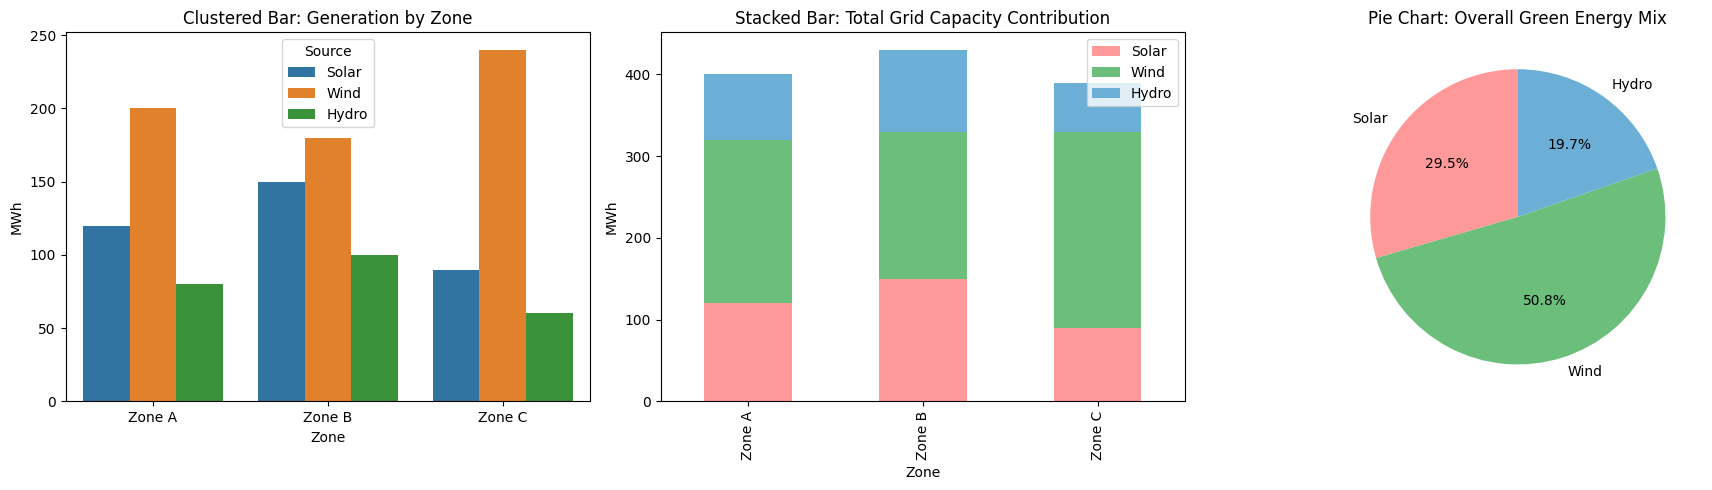

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Sample Data: Energy Generation (MWh) by Source across Sub Addressed Zones
df_bar = pd.DataFrame({
    'Zone': ['Zone A', 'Zone B', 'Zone C'],
    'Solar': [120, 150, 90],
    'Wind': [200, 180, 240],
    'Hydro': [80, 100, 60]
})

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Clustered Bar Chart
df_melted = df_bar.melt(id_vars='Zone', var_name='Source', value_name='MWh')
sns.barplot(x='Zone', y='MWh', hue='Source', data=df_melted, ax=axes[0])
axes[0].set_title("Clustered Bar: Generation by Zone")

# 2. Stacked Bar Chart
df_bar.set_index('Zone').plot(kind='bar', stacked=True, ax=axes[1], color=['#ff9999','#6bbf7b','#6baed6'])
axes[1].set_title("Stacked Bar: Total Grid Capacity Contribution")
axes[1].set_ylabel("MWh")

# 3. Pie Chart (Aggregate Generation Share)
total_gen = [df_bar['Solar'].sum(), df_bar['Wind'].sum(), df_bar['Hydro'].sum()]
axes[2].pie(total_gen, labels=['Solar', 'Wind', 'Hydro'], autopct='%1.1f%%', colors=['#ff9999','#6bbf7b','#6baed6'], startangle=90)
axes[2].set_title("Pie Chart: Overall Green Energy Mix")

plt.tight_layout()
plt.show()



2. Treemap & Waffle Chart

* Use Cases: Deconstructing large hierarchies (e.g., individual consumer loads contributing to a municipal aggregate) or clean grid distribution matrices without spatial angle distortion.

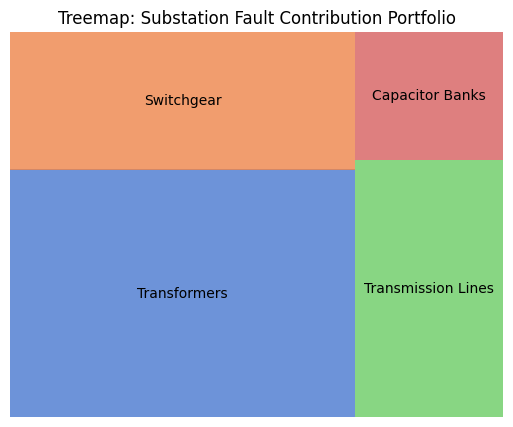

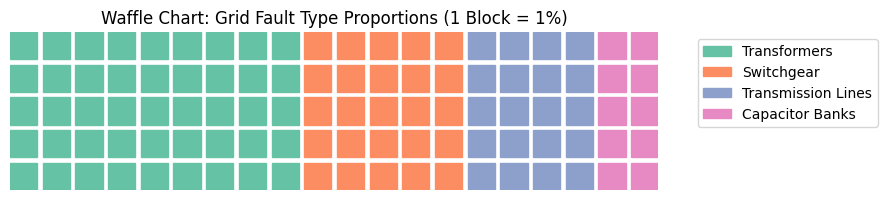

In [8]:
import squarify
from pywaffle import Waffle

# Sample Data: Distribution of Grid Faults by Sub-component
fault_data = {'Transformers': 45, 'Switchgear': 25, 'Transmission Lines': 20, 'Capacitor Banks': 10}

fig = plt.figure(figsize=(14, 5))

# 1. Treemap (Using Squarify)
ax1 = fig.add_subplot(1, 2, 1)
squarify.plot(sizes=list(fault_data.values()), label=list(fault_data.keys()),
              color=sns.color_palette("muted"), alpha=0.8, ax=ax1)
ax1.set_title("Treemap: Substation Fault Contribution Portfolio")
ax1.axis('off')

# 2. Waffle Chart (Using PyWaffle)
# Built inline using matplotlib's figure class structure
fig_waffle = plt.figure(
    FigureClass=Waffle,
    rows=5,
    columns=20,
    values=fault_data,
    legend={'loc': 'upper left', 'bbox_to_anchor': (1.05, 1)},
    figsize=(9, 4),
    title={'label': 'Waffle Chart: Grid Fault Type Proportions (1 Block = 1%)'}
)
plt.show()


**Group 2: Scientific, Dimensional & Advanced Telemetry**
3. Bubble Chart, Radar Chart, Polar Chart

* Use Cases: Visualizing multi-dimensional motor efficiency diagnostics (X=Current, Y=Voltage, Size=Temperature), phase-angle vectors, or harmonic distortions across fundamental angles.

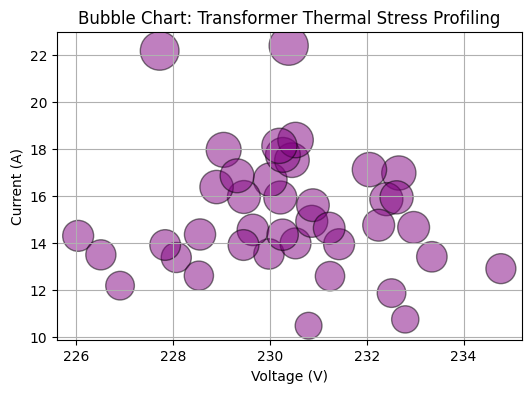

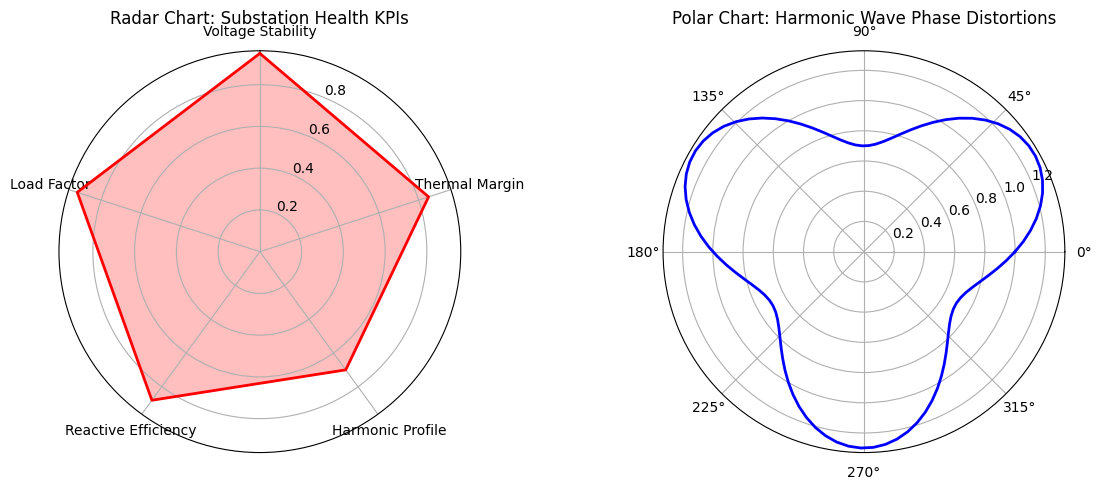

In [9]:
# 1. Bubble Chart
np.random.seed(10)
voltage_noise = np.random.normal(230, 2, 40)
current_noise = np.random.normal(15, 3, 40)
temp_core = (voltage_noise * current_noise) / 65  # Third dimension mapped to bubble size

plt.figure(figsize=(6, 4))
plt.scatter(voltage_noise, current_noise, s=temp_core*10, alpha=0.5, color='purple', edgecolors='black')
plt.title("Bubble Chart: Transformer Thermal Stress Profiling")
plt.xlabel("Voltage (V)")
plt.ylabel("Current (A)")
plt.grid(True)
plt.show()

# 2. Radar Chart vs Polar Chart
labels = ['Voltage Stability', 'Thermal Margin', 'Harmonic Profile', 'Reactive Efficiency', 'Load Factor']
num_vars = len(labels)

# Compute loop angles spanning 360 degrees
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1] # close the circular loop path

# Substation Performance Metrics
sub_a_metrics = [0.95, 0.85, 0.70, 0.88, 0.92]
sub_a_metrics += sub_a_metrics[:1]

fig, (ax_radar, ax_polar) = plt.subplots(1, 2, subplot_kw=dict(polar=True), figsize=(12, 5))

# Radar Plot Configuration
ax_radar.plot(angles, sub_a_metrics, color='red', linewidth=2)
ax_radar.fill(angles, sub_a_metrics, color='red', alpha=0.25)
ax_radar.set_theta_offset(np.pi / 2)
ax_radar.set_theta_direction(-1)
ax_radar.set_thetagrids(np.degrees(angles[:-1]), labels)
ax_radar.set_title("Radar Chart: Substation Health KPIs", pad=20)

# Polar Plot Configuration (Direct angle vs continuous wave magnitude)
theta = np.linspace(0, 2*np.pi, 100)
r = 1 + 0.3 * np.sin(3 * theta) # Simulated continuous 3rd harmonic phase vector
ax_polar.plot(theta, r, color='blue', lw=2)
ax_polar.set_title("Polar Chart: Harmonic Wave Phase Distortions", pad=20)

plt.tight_layout()
plt.show()


**Multi-dimensional data visualization**

To visualize multi-dimensional data (datasets with more than 2 or 3 variables), specialized chart types are required to pack extra attributes like categories, magnitudes, or hierarchies into a single 2D space.multi-dimensional charts for (e.g., Solar Inverter efficiency, Power Quality variables, and Smart Grid parameters).

1. Bubble Chart: Perfect for showing how two physical system constraints interact alongside operational thresholds (size) and asset risk matrices (color value).
2. Radar Chart: Standard tool for vendor selection when weighing hardware parameters such as cost vs reliability vs efficiency profiles.
3. Tree Map: Great for visualizing macro distributions inside smart cities or microgrid layout components.
4. Parallel Coordinates: Ideal for fault classification engines handling high-dimensional smart relay logs.



1. Multi-Dimensional Bubble Chart

A bubble chart extends a standard 2D scatter plot by mapping a 3rd dimension to bubble size and a 4th dimension to bubble color.

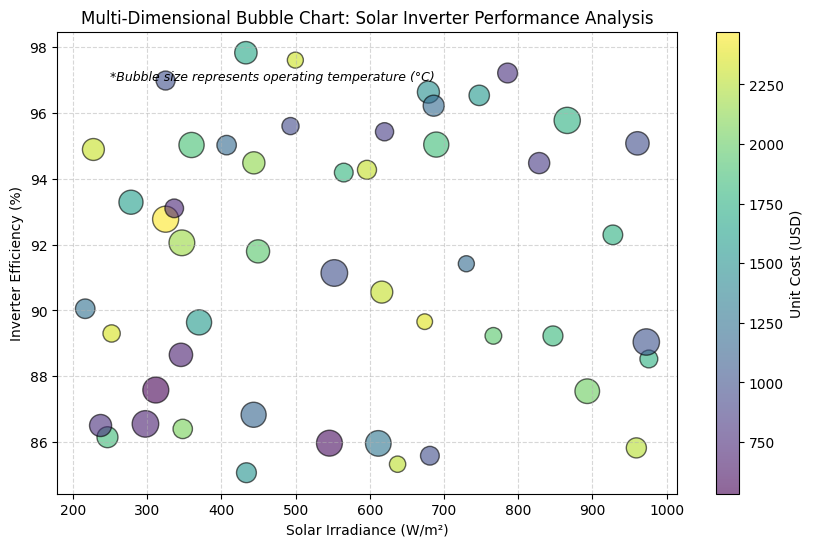

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Simulated data: 50 Solar Inverter Models
# Dim 1: Solar Irradiance (X), Dim 2: Efficiency (Y), Dim 3: Temperature (Size), Dim 4: Cost (Color)
np.random.seed(42)
data = {
    'Irradiance_W_m2': np.random.uniform(200, 1000, 50),
    'Efficiency_Pct': np.random.uniform(85, 98, 50),
    'Temperature_C': np.random.uniform(25, 75, 50),
    'Unit_Cost_USD': np.random.uniform(500, 2500, 50)
}
df_bubble = pd.DataFrame(data)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    x=df_bubble['Irradiance_W_m2'],
    y=df_bubble['Efficiency_Pct'],
    s=df_bubble['Temperature_C'] * 5,  # Scaling size for visibility
    c=df_bubble['Unit_Cost_USD'],
    cmap='viridis',
    alpha=0.6,
    edgecolors="black"
)

plt.title('Multi-Dimensional Bubble Chart: Solar Inverter Performance Analysis')
plt.xlabel('Solar Irradiance (W/m²)')
plt.ylabel('Inverter Efficiency (%)')

# Add Legend/Colorbar for the 3rd and 4th dimensions
cbar = plt.colorbar(scatter)
cbar.set_label('Unit Cost (USD)')
# Simple size handle reference
plt.text(250, 97, '*Bubble size represents operating temperature (°C)', fontsize=9, style='italic')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()



2. Radar (Spider) Chart

Radar charts are perfect for comparing multiple quantitative variables (3 or more) across different categories (e.g., comparing two types of electric motors over several performance metrics).

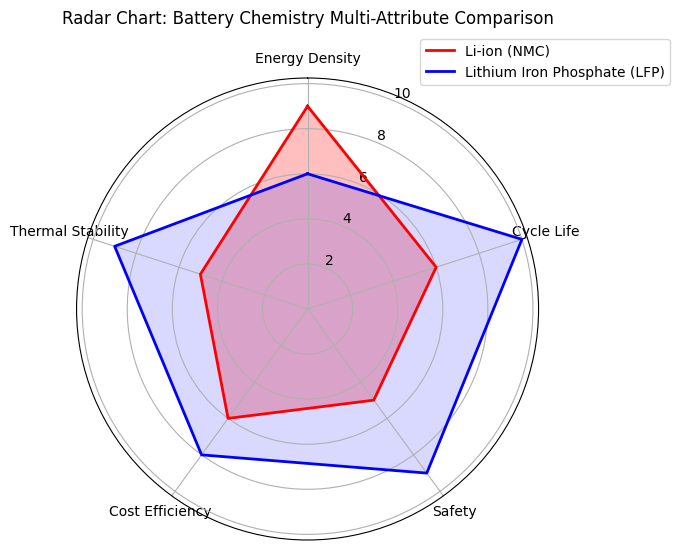

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# Metrics evaluated for two battery chemistries (Li-ion vs LFP)
labels = np.array(['Energy Density', 'Cycle Life', 'Safety', 'Cost Efficiency', 'Thermal Stability'])
num_vars = len(labels)

# Performance scores (out of 10)
li_ion = [9, 6, 5, 6, 5]
lfp = [6, 10, 9, 8, 9]

# Compute angle for each axis
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

# The plot must be circular/closed, so append the start value to the end.
labels = np.concatenate((labels, [labels[0]]))
angles += angles[:1]
li_ion += li_ion[:1]
lfp += lfp[:1]

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))

# Draw paths
ax.plot(angles, li_ion, color='red', linewidth=2, label='Li-ion (NMC)')
ax.fill(angles, li_ion, color='red', alpha=0.25)

ax.plot(angles, lfp, color='blue', linewidth=2, label='Lithium Iron Phosphate (LFP)')
ax.fill(angles, lfp, color='blue', alpha=0.15)

# Fix labels
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_thetagrids(np.degrees(angles[:-1]), labels[:-1])
plt.title('Radar Chart: Battery Chemistry Multi-Attribute Comparison', y=1.1)
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.show()



3. Tree Map

Tree maps display hierarchical structural data using nested rectangles. The area of each rectangle represents its relative magnitude, and the color can represent a secondary structural property.

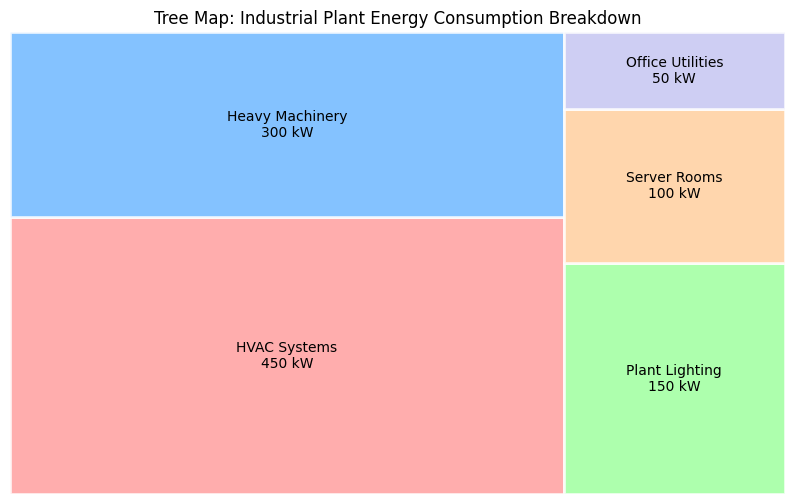

In [12]:
# Note: Requires 'squarify' package. Install via pip if needed: pip install squarify
import matplotlib.pyplot as plt
import squarify

# Data: Power consumption breakdown of an Industrial Plant
sizes = [450, 300, 150, 100, 50] # Total load allocation in kW
labels = [
    'HVAC Systems\n450 kW',
    'Heavy Machinery\n300 kW',
    'Plant Lighting\n150 kW',
    'Server Rooms\n100 kW',
    'Office Utilities\n50 kW'
]
colors = ['#ff9999','#66b3ff','#99ff99','#ffcc99', '#c2c2f0']

plt.figure(figsize=(10, 6))
squarify.plot(sizes=sizes, label=labels, color=colors, alpha=0.8, edgecolor="white", linewidth=2)

plt.title('Tree Map: Industrial Plant Energy Consumption Breakdown')
plt.axis('off') # Turn off the surrounding graph axes
plt.show()



4. Parallel Coordinates Plot

For datasets with 5 or more dimensions, a parallel coordinates plot allows you to map every parameter side-by-side to track multidimensional profiles across different classifications.

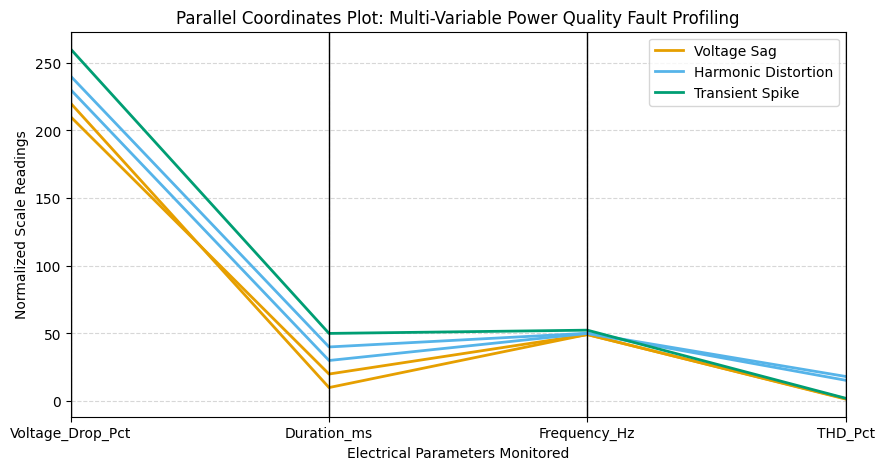

In [13]:
import matplotlib.pyplot as plt
import pandas as pd
from pandas.plotting import parallel_coordinates

# Simulated data: Power Quality Disturbances across 3 Fault Types
data = {
    'Fault_Type': ['Voltage Sag', 'Voltage Sag', 'Harmonic Distortion', 'Harmonic Distortion', 'Transient Spike'],
    'Voltage_Drop_Pct':[220,210,230,240,260],
    'Duration_ms':[10,20,30,40,50],
    'Frequency_Hz': [49.2, 49.1, 50.0, 50.1, 52.4],
    'THD_Pct': [1.5, 1.8, 15.4, 18.2, 2.1] # Total Harmonic Distortion
}
df_parallel = pd.DataFrame(data)

plt.figure(figsize=(10, 5))
parallel_coordinates(df_parallel, 'Fault_Type', color=('#E69F00', '#56B4E9', '#009E73'), linewidth=2)

plt.title('Parallel Coordinates Plot: Multi-Variable Power Quality Fault Profiling')
plt.xlabel('Electrical Parameters Monitored')
plt.ylabel('Normalized Scale Readings')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


**Experiment7: Graph Data Visualization**
Graph Data Visualization refers to displaying network structures composed of nodes (vertices representing entities like power substations, buses, or computer servers) and edges (lines representing connections like transmission lines, communication links, or transformers).
The industry standard library for network structures in Python is networkx. For visualization, we pair it with matplotlib. Below are implementations tracking a typical Electrical Power Grid Network and a Sensor Communication Topology.

1. Network Traversal Algorithms: By mapping electrical substations as node objects, engineers execute Shortest Path Algorithms (nx.shortest_path) to figure out alternate power lines to route electricity instantly when a high-voltage tower fails.
2. Connectivity and Vulnerability Analysis: Calculating graph metrics like Degree Centrality isolates key points of single-point-of-failure vulnerability inside your scada infrastructure or communication hubs.



1. Power Distribution Grid Topology (Directed Graph)

This example visualizes the directional flow of electrical power from a central generation plant down to transmission substations and localized distribution grids.

In [14]:
pip install networkx matplotlib

Note: you may need to restart the kernel to use updated packages.


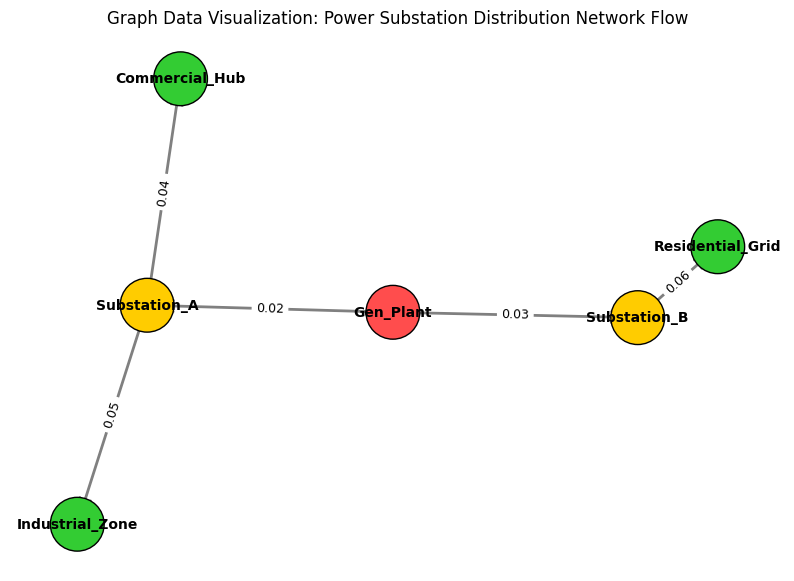

In [15]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. Initialize a Directed Graph (DiGraph) representing power flow
G_power = nx.DiGraph()

# 2. Add structural nodes with explicit engineering parameters
G_power.add_node("Gen_Plant", type="Source", power="500MW")
G_power.add_node("Substation_A", type="Transmission", capacity="250MW")
G_power.add_node("Substation_B", type="Transmission", capacity="250MW")
G_power.add_node("Industrial_Zone", type="Load", demand="200MW")
G_power.add_node("Residential_Grid", type="Load", demand="150MW")
G_power.add_node("Commercial_Hub", type="Load", demand="100MW")

# 3. Add directional edges representing high-voltage lines with line loss weights
G_power.add_edge("Gen_Plant", "Substation_A", loss=0.02)
G_power.add_edge("Gen_Plant", "Substation_B", loss=0.03)
G_power.add_edge("Substation_A", "Industrial_Zone", loss=0.05)
G_power.add_edge("Substation_A", "Commercial_Hub", loss=0.04)
G_power.add_edge("Substation_B", "Residential_Grid", loss=0.06)

# 4. Set node colors based on their structural role in the grid
color_map = []
for node, attrs in G_power.nodes(data=True):
    if attrs['type'] == "Source":
        color_map.append('#ff4d4d')  # Red for Generation
    elif attrs['type'] == "Transmission":
        color_map.append('#ffcc00')  # Yellow for Substation
    else:
        color_map.append('#33cc33')  # Green for End Consumers

# 5. Render the network plot
plt.figure(figsize=(10, 7))
pos = nx.spring_layout(G_power, seed=42)  # Structured algorithm layout

nx.draw_networkx_nodes(G_power, pos, node_size=1500, node_color=color_map, edgecolors='black')
nx.draw_networkx_edges(G_power, pos, width=2, arrowsize=20, arrowstyle='->', edge_color='gray')
nx.draw_networkx_labels(G_power, pos, font_size=10, font_weight='bold')

# Edge labels to show line loss parameters
edge_labels = nx.get_edge_attributes(G_power, 'loss')
nx.draw_networkx_edge_labels(G_power, pos, edge_labels=edge_labels, font_size=9)

plt.title("Graph Data Visualization: Power Substation Distribution Network Flow")
plt.axis('off')
plt.show()



2. Mesh Network Topology (Undirected Weighted Graph)

This script models an IoT Smart Meter Mesh Network where sensor nodes dynamically communicate with neighboring routers to relay power consumption telemetry back to a central gateway.

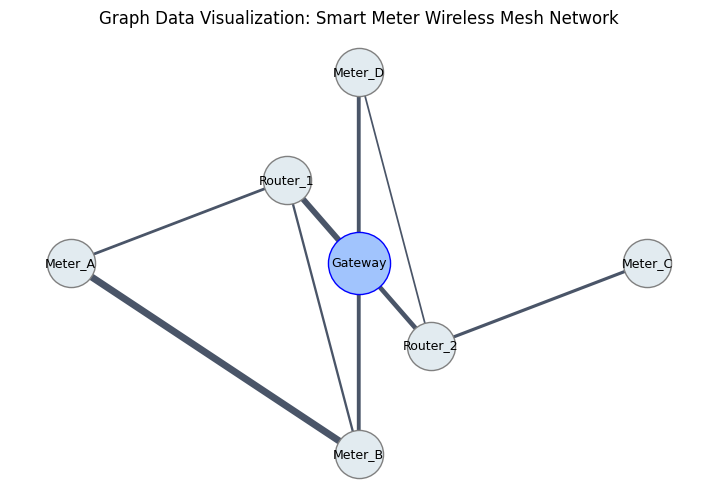

In [16]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. Initialize an Undirected Weighted Graph for bidirectional telemetry lines
G_mesh = nx.Graph()

# 2. Define communication links with path distance/latency values as weights
# Form: (Node1, Node2, Latency_ms)
links = [
    ('Gateway', 'Router_1', 12),
    ('Gateway', 'Router_2', 15),
    ('Router_1', 'Meter_A', 25),
    ('Router_1', 'Meter_B', 30),
    ('Router_2', 'Meter_C', 22),
    ('Router_2', 'Meter_D', 40),
    ('Meter_B', 'Meter_D', 18),   # Mesh cross-link connection
    ('Meter_A', 'Meter_B', 10)    # Local communication link
]

G_mesh.add_weighted_edges_from(links)

# 3. Position calculations using a shell/concentric layout model
pos_mesh = nx.shell_layout(G_mesh, [['Gateway'], ['Router_1', 'Router_2'], ['Meter_A', 'Meter_B', 'Meter_C', 'Meter_D']])

# 4. Render the topology chart
plt.figure(figsize=(9, 6))

# Highlight the Gateway node using size differentiation
nx.draw_networkx_nodes(G_mesh, pos_mesh, nodelist=['Gateway'], node_size=2000, node_color='#a1c4fd', edgecolors='blue')
nx.draw_networkx_nodes(G_mesh, pos_mesh, nodelist=[n for n in G_mesh if n != 'Gateway'], node_size=1200, node_color='#e2ebf0', edgecolors='gray')

# Draw links using weights to determine line widths (Lower latency = thicker line)
weights = [50 / G_mesh[u][v]['weight'] for u, v in G_mesh.edges()]
nx.draw_networkx_edges(G_mesh, pos_mesh, width=weights, edge_color='#4a5568')

nx.draw_networkx_labels(G_mesh, pos_mesh, font_size=9, font_family='sans-serif')

plt.title("Graph Data Visualization: Smart Meter Wireless Mesh Network")
plt.axis('off')
plt.show()
